# IS 362 – Week 8 Assignment: Auto MPG Exploratory Data Analysis

Data source: [UCI Auto MPG](https://archive.ics.uci.edu/ml/datasets/Auto+MPG). The data is pulled directly from the repository, and all cleanup is done in code so the notebook is fully reproducible.

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='darkgrid')

## 1–3. Load the data and name the columns

Column names come from the attribute list in `auto-mpg.names`. The file is whitespace-delimited, and the car name is a quoted string containing spaces.

In [50]:
URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data'

columns = ['mpg', 'cylinders', 'displacement', 'horsepower',
           'weight', 'acceleration', 'model_year', 'origin', 'car_name']

auto = pd.read_csv(URL, sep=r'\s+', names=columns, quotechar='"')
auto.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


## 2. Review the data

In [51]:
print(auto.shape)
auto.info()

(398, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [52]:
auto.describe(include='all')

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
count,398.000000,398.000000,398.000000,398,398.000000,398.000000,398.000000,398.000000,398
unique,NaN,NaN,NaN,94,NaN,NaN,NaN,NaN,305
top,NaN,NaN,NaN,150.0,NaN,NaN,NaN,NaN,ford pinto
freq,NaN,NaN,NaN,22,NaN,NaN,NaN,NaN,6
mean,23.514573,5.454774,193.425879,NaN,2970.424623,15.568090,76.010050,1.572864,NaN
std,7.815984,1.701004,104.269838,NaN,846.841774,2.757689,3.697627,0.802055,NaN
min,9.000000,3.000000,68.000000,NaN,1613.000000,8.000000,70.000000,1.000000,NaN
25%,17.500000,4.000000,104.250000,NaN,2223.750000,13.825000,73.000000,1.000000,NaN
50%,23.000000,4.000000,148.500000,NaN,2803.500000,15.500000,76.000000,1.000000,NaN
75%,29.000000,8.000000,262.000000,NaN,3608.000000,17.175000,79.000000,2.000000,NaN


## 4. Handle missing horsepower values

Missing horsepower is marked with `'?'`, which makes pandas read the column as text. Replace it with `NaN`, then convert the column to numeric.

In [53]:
print('Rows with ? in horsepower:', (auto['horsepower'] == '?').sum())

auto['horsepower'] = auto['horsepower'].replace('?', np.nan)
auto['horsepower'] = pd.to_numeric(auto['horsepower'])

print(auto['horsepower'].dtype)
print('Missing horsepower values:', auto['horsepower'].isna().sum())

Rows with ? in horsepower: 6
float64
Missing horsepower values: 6


## 5. Convert `origin` codes to labels

Mapping exactly as specified in the assignment: 1 → USA, 2 → Asia, 3 → Europe.

> **Note:** `auto-mpg.names` actually describes the codes as 1 = American, 2 = European, 3 = Japanese. If you'd rather match the dataset documentation, change the dictionary to `{1: 'USA', 2: 'Europe', 3: 'Asia'}`.

In [54]:
origin_map = {1: 'USA', 2: 'Asia', 3: 'Europe'}
auto['origin'] = auto['origin'].map(origin_map)

auto['origin'].value_counts()

,count
origin,
USA,249
Europe,79
Asia,70


In [55]:
auto.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,USA,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,USA,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,USA,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,USA,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,USA,ford torino


## 6. Distribution of cylinders

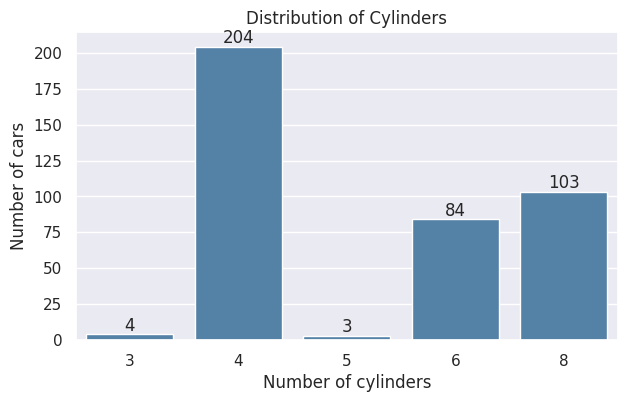

In [56]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=auto, x='cylinders', color='steelblue', ax=ax)
ax.set_title('Distribution of Cylinders')
ax.set_xlabel('Number of cylinders')
ax.set_ylabel('Number of cars')
for container in ax.containers:
    ax.bar_label(container)
plt.show()

Four-cylinder engines are the most common in the dataset, followed by eight- and six-cylinder engines. Three- and five-cylinder engines are rare.

## 7. Horsepower vs. weight

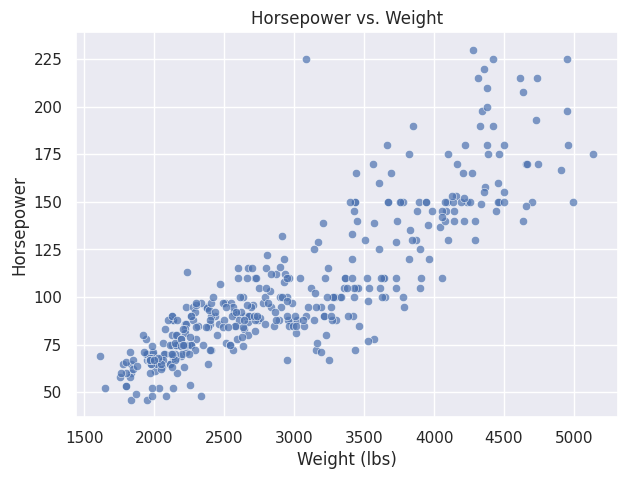

Correlation: 0.865


In [57]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=auto, x='weight', y='horsepower', alpha=0.7, ax=ax)
ax.set_title('Horsepower vs. Weight')
ax.set_xlabel('Weight (lbs)')
ax.set_ylabel('Horsepower')
plt.show()

print('Correlation:', round(auto['weight'].corr(auto['horsepower']), 3))

There is a clear positive relationship: heavier cars tend to have more horsepower. The spread widens at higher weights.

## 8. Question: Has fuel efficiency improved over time, and does the trend differ by origin?

I'll look at average `mpg` by `model_year`, split by `origin`, and then at how `mpg` relates to `weight` for each origin.

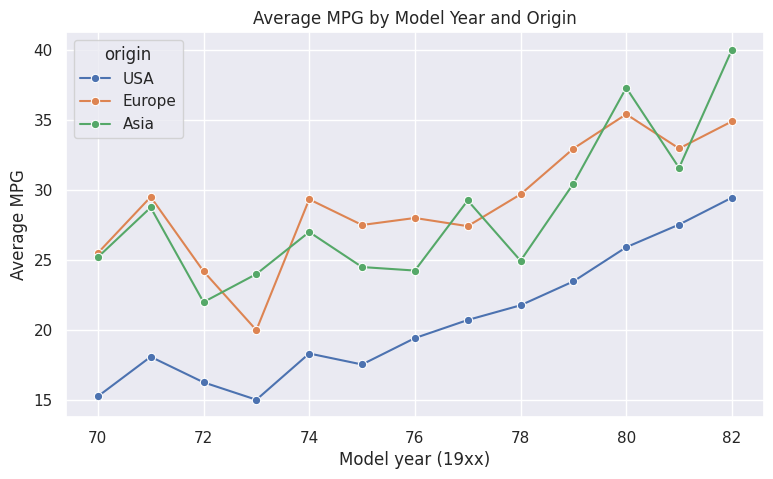

In [58]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=auto, x='model_year', y='mpg', hue='origin',
             estimator='mean', errorbar=None, marker='o', ax=ax)
ax.set_title('Average MPG by Model Year and Origin')
ax.set_xlabel('Model year (19xx)')
ax.set_ylabel('Average MPG')
plt.show()

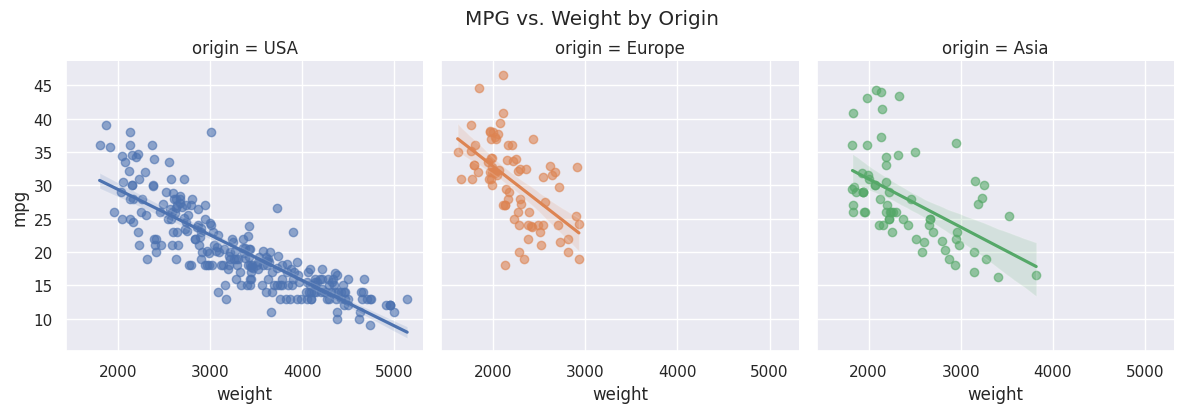

In [59]:
g = sns.lmplot(data=auto, x='weight', y='mpg', col='origin', hue='origin',
               height=4, aspect=1, scatter_kws={'alpha': 0.6})
g.figure.suptitle('MPG vs. Weight by Origin', y=1.03)
plt.show()

In [60]:
auto.groupby('origin')[['mpg', 'weight', 'horsepower']].mean().round(1)

,mpg,weight,horsepower
origin,,,
Asia,27.9,2423.3,80.6
Europe,30.5,2221.2,79.8
USA,20.1,3361.9,119.0


### Answer

Fuel efficiency rose substantially from 1970 to 1982 for cars from every origin, with the steepest gains in the mid-to-late 1970s. Cars from Asia and Europe have a higher average MPG than those from the USA in nearly every year, and the USA group is on average heavier with more horsepower, which fits the second chart: within each origin, heavier cars get lower MPG, and USA cars are concentrated at the heavy, low-MPG end. The improvement over time therefore reflects both more efficient designs and, for the USA, a shift toward lighter cars.